# 02 · Business health KPIs & exploratory analysis
**Business question:** *Is the business growing — and is growth coming from more customers, more orders, or bigger orders?*

Fiscal years are defined **Dec–Nov** so both years have 12 complete months (Dec-2011 is partial).

In [1]:
import sys, pandas as pd
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
T = ROOT / 'reports' / 'tables'; F = ROOT / 'reports' / 'figures'
def fig(name): display(Image(filename=str(F / f'{name}.png')))

In [2]:
pd.read_csv(T / 'sql_kpi_fy_comparison.csv')

,fiscal_year,net_merch_revenue,gross_merch_sales,guest_sales,identified_sales,active_customers,identified_orders,orders_per_customer,identified_aov,return_rate
0,FY2010,"9,146,264.744","9,240,528.434","1,065,287.220","8,175,241.214",4227,18060,4.273,452.670,0.010
1,FY2011,"9,299,896.273","9,377,245.743","1,407,728.840","7,969,516.903",4284,17509,4.087,455.170,0.008


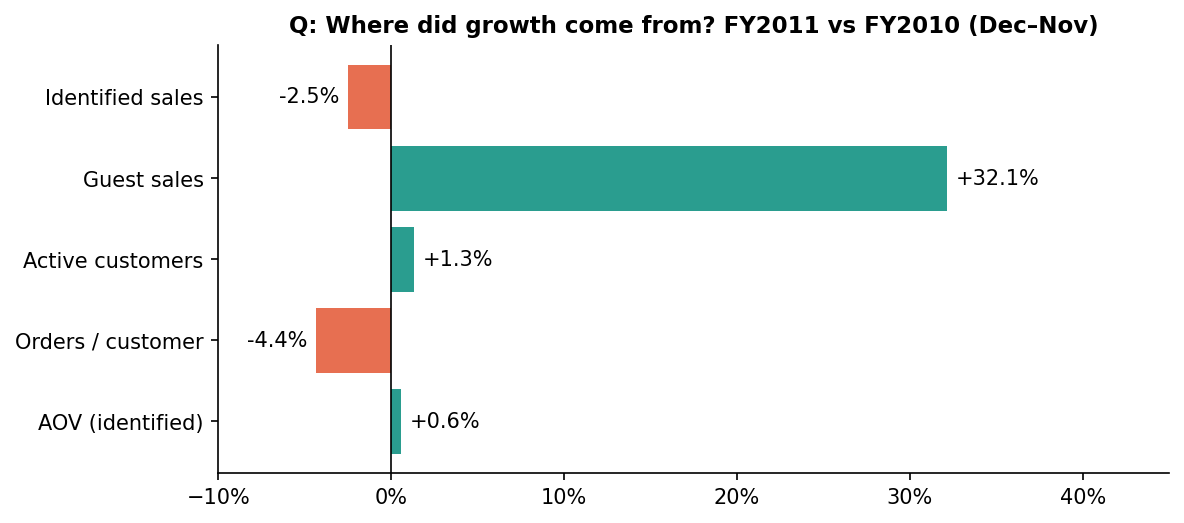

In [3]:
fig('02_fy_growth_drivers')

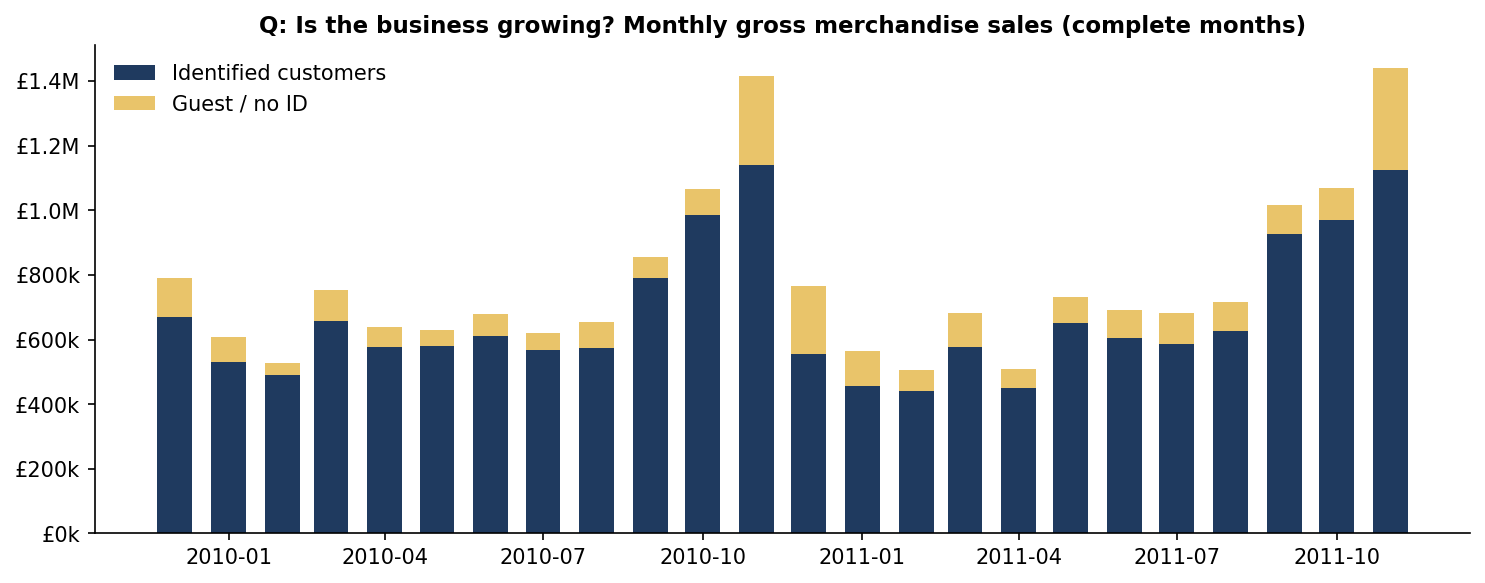

In [4]:
fig('01_monthly_sales_identified_vs_guest')

**Read-out (calculated):** merchandise revenue grew +1.7%, but identified-customer sales fell −2.5% while guest sales rose +32%. Orders per customer fell −4.4%; AOV was flat (+0.6%). Sales are strongly seasonal — Sep–Nov is the peak.

In [5]:
pd.read_csv(T / 'sql_kpi_yoy_retention.csv').T

,0
customers_fy10,"4,227.000"
retained_customers,"2,699.000"
customer_retention_rate,0.638
new_or_reactivated_fy11,"1,585.000"
revenue_fy10,"8,085,112.564"
revenue_fy11_from_fy10_base,"6,533,630.762"
net_revenue_retention,0.808
revenue_lost_from_churned,"1,021,571.113"


**Read-out:** only 64% of FY2010 customers bought again in FY2011; net revenue retention was 81%. Customers who did not return took ~£1.0M of prior-year revenue with them.

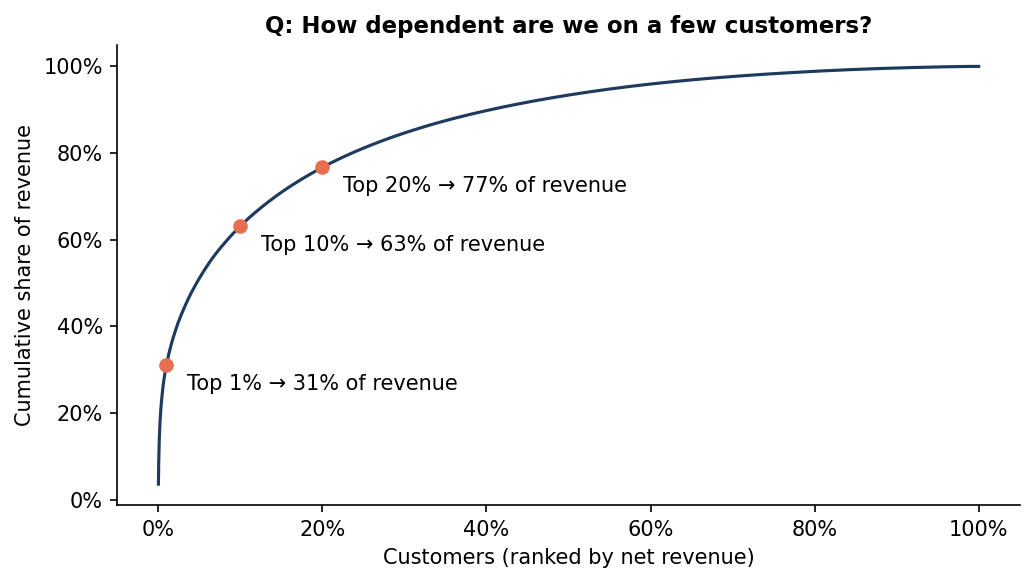

,band,cumulative_revenue_share
0,Top 10 customers,0.163
1,Top 1%,0.310
2,Top 5%,0.510
3,Top 10%,0.631
4,Top 20%,0.767
5,Top 50%,0.934
6,All,1.000


In [6]:
fig('06_customer_concentration_pareto'); pd.read_csv(T / 'sql_customer_concentration.csv')

In [7]:
pd.read_csv(T / 'sql_market_mix.csv')

,region,customers,net_revenue,pct_revenue,avg_orders,median_customer_revenue
0,UK,5326,"13,623,252.000",0.835,6.220,816.000
1,Europe (ex-UK),452,"2,428,884.000",0.149,6.660,"1,126.000"
2,Rest of World,55,"260,160.000",0.016,3.050,"1,002.000"
3,Unspecified,6,"8,597.000",0.001,2.670,546.000


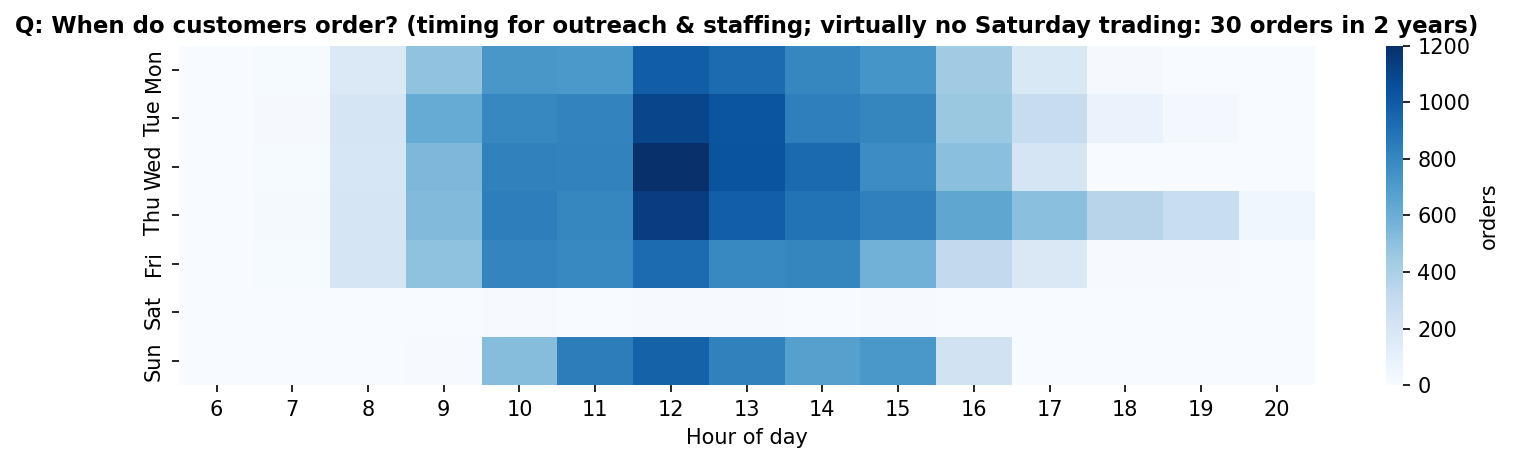

In [8]:
fig('12_order_timing')

## What should management do differently?
1. **Stop reading headline growth as healthy.** Growth came from unidentifiable buyers while the identified base shrank. Report identified and guest revenue separately every month.
2. **Treat retention as the primary growth lever**: a 64% customer retention rate and 81% NRR mean the business must replace ~19% of its revenue every year just to stand still.
3. **Run a key-account programme**: the top 1% of customers generate ~31% of revenue — losing a handful would be material.
4. **Time outreach to buying behaviour**: ~78% of orders are placed between 10:00 and 16:00 (peak at noon), and there is virtually no Saturday trading.